# 実験3 (論文 第4.3.5〜4.3.6節, 第6.5.2〜6.5.4節): パターン分類ベンチマーク

交差エントロピー損失＋Softmax 出力層による多クラス分類問題において，1次手法 (`Adam`)，共役勾配法 (`CG-HS`)，
フル行列2次手法 (`QN, MSQN, NAQ, AdaNAQ, MoQ, AdaMoQ`)，記憶制限手法 (`LQN, LNAQ, LMoQ`)，およびメモリレス手法 (`MLQN, MLNAQ, MLMoQ`) を比較する．

- **実験 3A (Three-Spirals)**: `2-10-3` ($d=63$, $|T_r|=1,050$, $|T_e|=1,050$, $R=10$)
- **実験 3B ($8\times 8$ 手書き風数字分類)**: `64-10-10` ($d=750$, $|T_r|=1,347$, $|T_e|=450$, $R=10$)
- **実験 3C ($28\times 28$ 高次元数字分類)**: `784-10-10` ($d=7,960$, $|T_r|=12,000$, $|T_e|=2,000$, $R=10$)

In [1]:
import os
import sys
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
os.environ.setdefault('MPLCONFIGDIR', os.path.join(os.getcwd(), '.mplconfig'))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from model import BatchedClassifier
from utils import (
    setup_japanese_matplotlib,
    load_or_create_three_spirals_dataset,
    load_or_create_digits_8x8_dataset,
    load_or_create_digits_28x28_dataset,
    generate_initial_weights,
    run_classification_batched,
    format_cls_dataframe,
)

setup_japanese_matplotlib()
os.makedirs('../report/img', exist_ok=True)
os.makedirs('../datasets', exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch: {torch.__version__}, Device: {device}')

PyTorch: 2.7.1+cu118, Device: cuda


## 1. 実験 3A: Three-Spirals 3クラス分類 (`2-10-3`, $d=63$, $R=10$)

In [2]:
ds_sp = load_or_create_three_spirals_dataset(dataset_dir='../datasets', seed=2023, device=device)
print(f"Spirals Train: {tuple(ds_sp['X_train_64'].shape)}, Test: {tuple(ds_sp['X_test_64'].shape)}")

n_in_3a, n_hid_3a, n_out_3a = 2, 10, 3
d_w_3a = n_in_3a * n_hid_3a + n_hid_3a + n_hid_3a * n_out_3a + n_out_3a  # 63
R = 10
w_init_3a = generate_initial_weights(R, d_w_3a, seed=2023, device=device)

algos_3a = (
    'Adam', 'CG', 'QN', 'MSQN', 'NAQ', 'AdaNAQ', 'MoQ', 'AdaMoQ',
    'LQN', 'LNAQ', 'LMoQ', 'MLQN', 'MLNAQ', 'MLMoQ'
)
res_3a_list = []
res_3a_map = {}
for algo in algos_3a:
    r = run_classification_batched(
        algo=algo, w_init=w_init_3a, ds=ds_sp,
        n_in=n_in_3a, n_hid=n_hid_3a, n_out=n_out_3a, memory_size=8,
        max_epochs=1500, check_interval=50, record_stride=25, show_pbar=False
    )
    res_3a_list.append(r)
    res_3a_map[algo] = r
    print(f"{algo:8s} | E_tr_med={r['train_median']:.3f} | Acc_tr_med={r['acc_train_median']:.2f}% | Acc_te_med={r['acc_test_median']:.2f}% | Iters={r['ave_epochs']:.1f}")

df_3a = format_cls_dataframe(res_3a_list)
df_3a.to_csv('../datasets/ex003_three_spirals_results.csv', index=False, encoding='utf-8')
df_3a

Spirals Train: (1050, 2), Test: (1050, 2)
Adam     | E_tr_med=36.848 | Acc_tr_med=100.00% | Acc_te_med=99.81% | Iters=1500.0
CG       | E_tr_med=119.592 | Acc_tr_med=98.19% | Acc_te_med=97.71% | Iters=1500.0
QN       | E_tr_med=0.000 | Acc_tr_med=100.00% | Acc_te_med=99.62% | Iters=320.1
MSQN     | E_tr_med=0.000 | Acc_tr_med=100.00% | Acc_te_med=99.57% | Iters=365.1
NAQ      | E_tr_med=0.000 | Acc_tr_med=100.00% | Acc_te_med=99.71% | Iters=230.1
AdaNAQ   | E_tr_med=0.000 | Acc_tr_med=100.00% | Acc_te_med=99.67% | Iters=250.1
MoQ      | E_tr_med=0.001 | Acc_tr_med=100.00% | Acc_te_med=99.57% | Iters=440.0
AdaMoQ   | E_tr_med=0.001 | Acc_tr_med=100.00% | Acc_te_med=99.62% | Iters=510.0
LQN      | E_tr_med=0.000 | Acc_tr_med=100.00% | Acc_te_med=99.43% | Iters=150.1
LNAQ     | E_tr_med=0.000 | Acc_tr_med=100.00% | Acc_te_med=99.71% | Iters=105.2
LMoQ     | E_tr_med=0.000 | Acc_tr_med=100.00% | Acc_te_med=99.81% | Iters=115.1
MLQN     | E_tr_med=0.001 | Acc_tr_med=100.00% | Acc_te_med=99.

,Algorithm,m,E_train (x10^3) Med/Ave/Best/Worst,Est. Time(s),Per Iter(ms),Ave. Iters,Acc_train(%) Med/Ave/Best/Worst,Acc_test(%) Med/Ave/Best/Worst,Conv(%)
0,Adam,-,36.848 / 36.168 / 25.521 / 55.178,0.128,0.085,1500,100.00 / 99.93 / 100.00 / 99.62,99.81 / 99.71 / 99.81 / 99.52,100.0
1,CG,-,119.592 / 123.329 / 91.438 / 155.634,0.199,0.132,1500,98.19 / 98.12 / 99.62 / 96.10,97.71 / 97.69 / 98.76 / 96.10,100.0
2,QN,-,0.000 / 0.002 / 0.000 / 0.014,0.075,0.235,320,100.00 / 100.00 / 100.00 / 100.00,99.62 / 99.56 / 99.90 / 99.05,100.0
3,MSQN,-,0.000 / 0.001 / 0.000 / 0.002,0.120,0.329,365,100.00 / 100.00 / 100.00 / 100.00,99.57 / 99.54 / 100.00 / 99.05,100.0
4,NAQ,-,0.000 / 0.000 / 0.000 / 0.001,0.098,0.426,230,100.00 / 100.00 / 100.00 / 100.00,99.71 / 99.59 / 100.00 / 98.76,100.0
5,AdaNAQ,-,0.000 / 0.529 / 0.000 / 5.284,0.101,0.402,250,100.00 / 99.99 / 100.00 / 99.90,99.67 / 99.47 / 99.90 / 98.57,100.0
6,MoQ,-,0.001 / 0.001 / 0.000 / 0.002,0.263,0.597,440,100.00 / 100.00 / 100.00 / 100.00,99.57 / 99.50 / 99.90 / 98.57,100.0
7,AdaMoQ,-,0.001 / 0.001 / 0.000 / 0.002,0.282,0.554,510,100.00 / 100.00 / 100.00 / 100.00,99.62 / 99.58 / 99.90 / 98.57,100.0
8,LQN,8,0.000 / 0.000 / 0.000 / 0.001,0.087,0.581,150,100.00 / 100.00 / 100.00 / 100.00,99.43 / 99.50 / 99.90 / 99.24,100.0
9,LNAQ,8,0.000 / 0.000 / 0.000 / 0.001,0.062,0.587,105,100.00 / 100.00 / 100.00 / 100.00,99.71 / 99.69 / 100.00 / 99.24,100.0


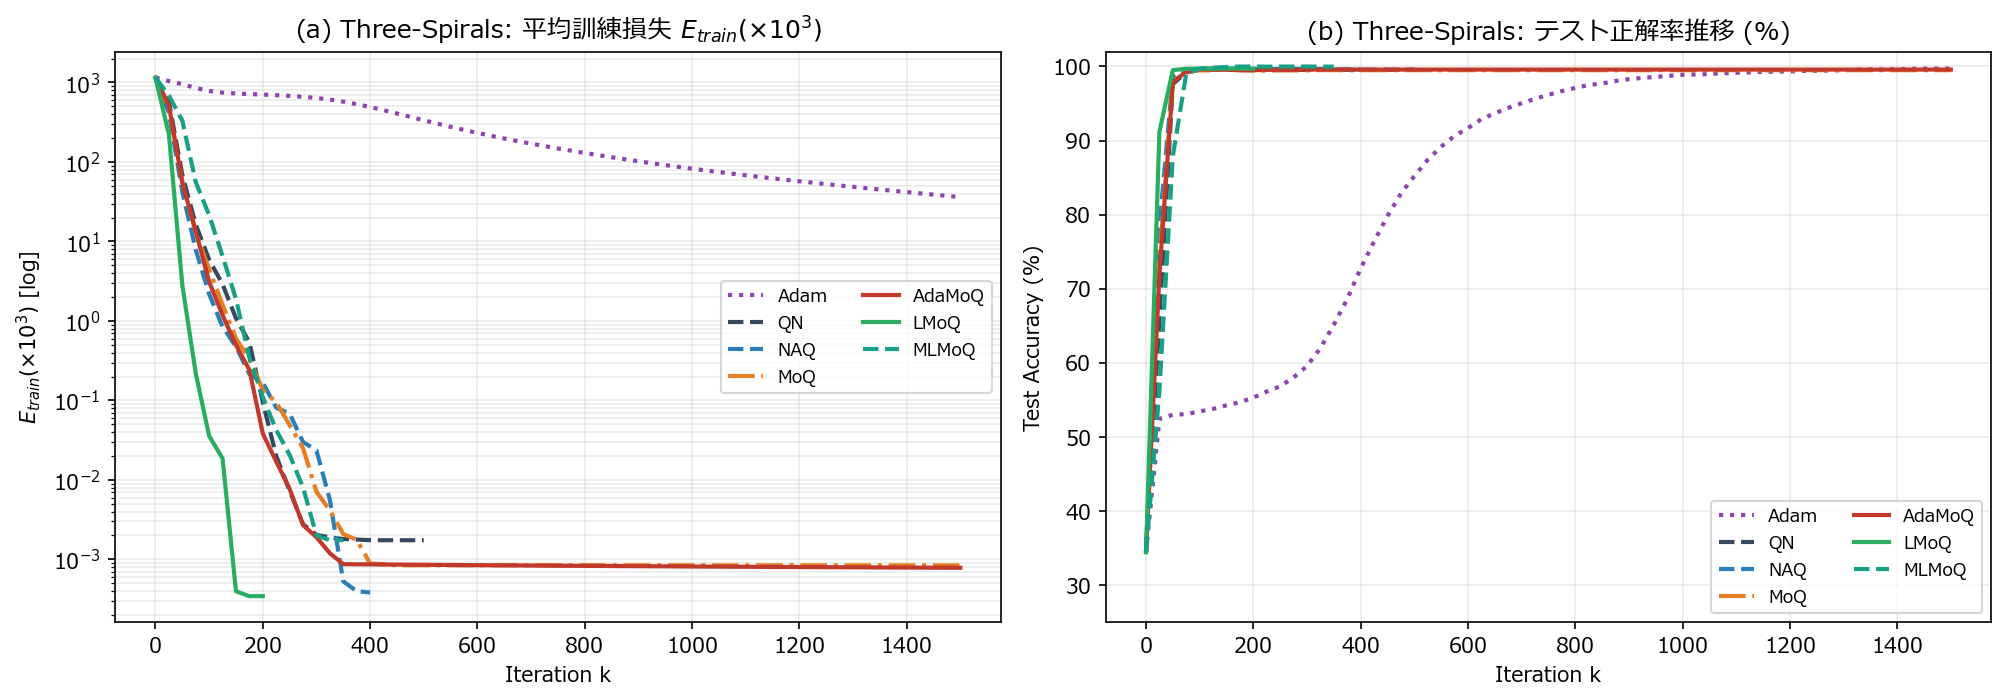

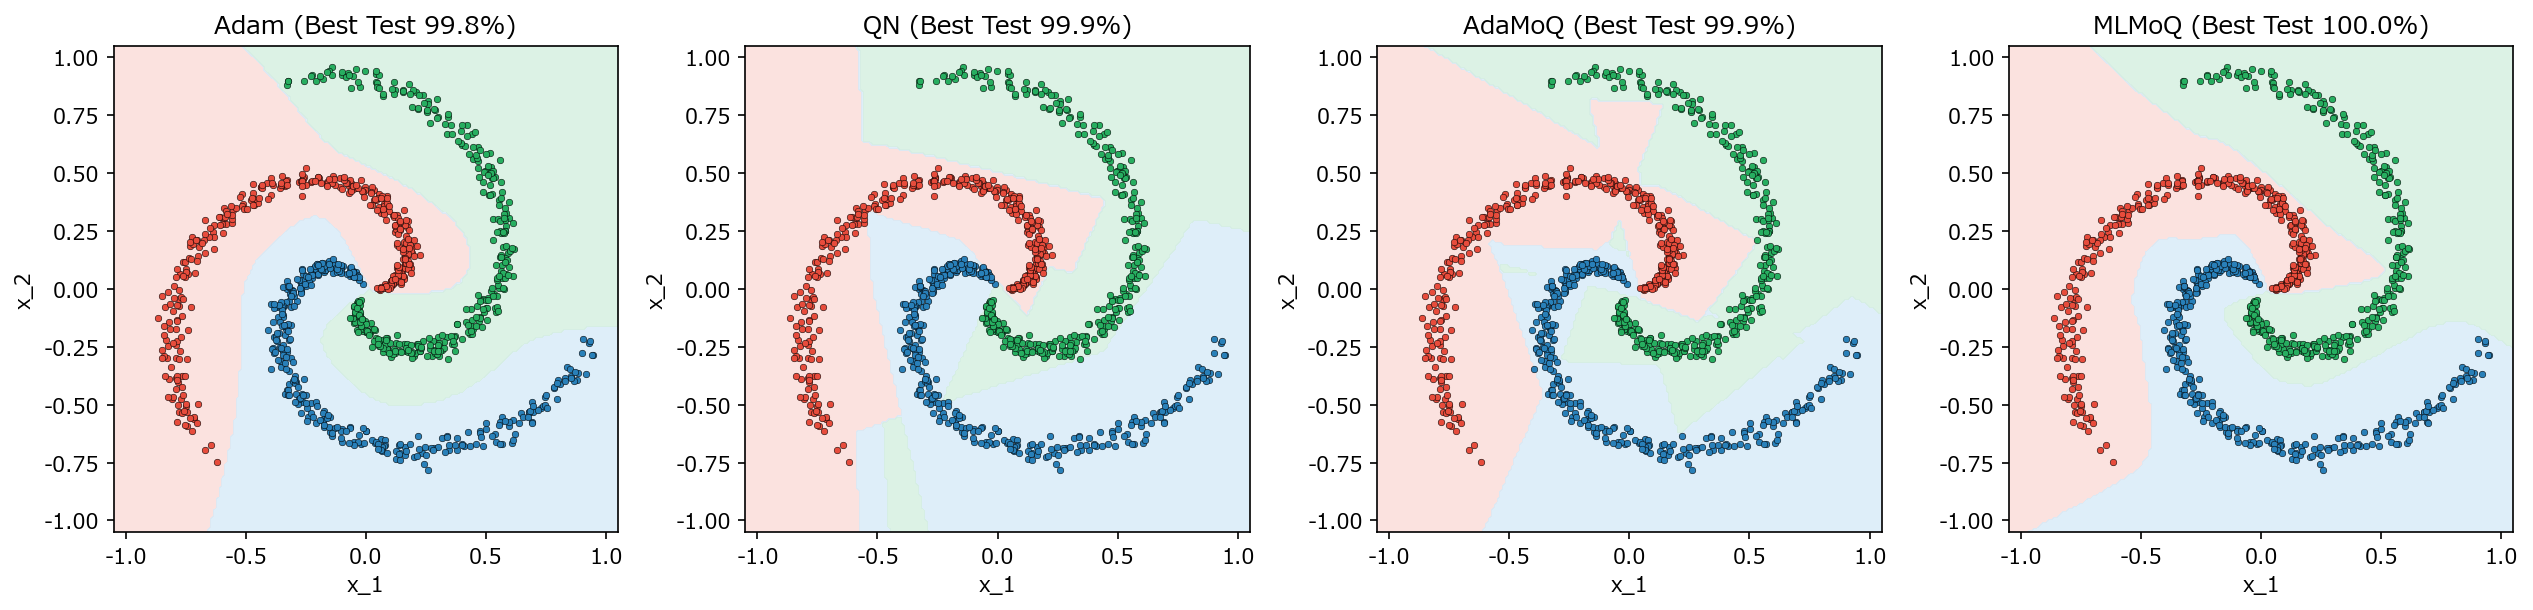

In [3]:
# 図1: Three-Spirals 収束曲線 (交差エントロピー損失 & テスト正解率)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
plot_3a = [
    ('Adam', '#8e44ad', ':'), ('QN', '#34495e', '--'), ('NAQ', '#2980b9', '--'),
    ('MoQ', '#e67e22', '-.'), ('AdaMoQ', '#c0392b', '-'),
    ('LMoQ', '#27ae60', '-'), ('MLMoQ', '#16a085', '--')
]
for name, col, ls in plot_3a:
    r = res_3a_map[name]
    axes[0].plot(r['rec_epochs'], np.clip(r['rec_means'] * 1e3, 1e-4, None), label=name, color=col, linestyle=ls, linewidth=2.0)
    axes[1].plot(r['rec_epochs'], r['rec_te_accs'], label=name, color=col, linestyle=ls, linewidth=2.0)

axes[0].set_yscale('log')
axes[0].set_title('(a) Three-Spirals: 平均訓練損失 $E_{train} (\\times 10^3)$')
axes[0].set_xlabel('Iteration k'); axes[0].set_ylabel('$E_{train} (\\times 10^3)$ [log]')
axes[0].legend(fontsize=8.5, ncol=2); axes[0].grid(alpha=0.25, which='both')

axes[1].set_title('(b) Three-Spirals: テスト正解率推移 (%)')
axes[1].set_xlabel('Iteration k'); axes[1].set_ylabel('Test Accuracy (%)')
axes[1].set_ylim(25, 102)
axes[1].legend(fontsize=8.5, ncol=2); axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig('../report/img/ex003_spirals_convergence.png', dpi=150, bbox_inches='tight')
plt.show()

# 図2: Three-Spirals 決定境界比較 (Adam, QN, AdaMoQ, MLMoQ)
bcls_3a = BatchedClassifier(n_in_3a, n_hid_3a, n_out_3a)
xx, yy = np.meshgrid(np.linspace(-1.05, 1.05, 180), np.linspace(-1.05, 1.05, 180))
grid_t = torch.tensor(np.c_[xx.ravel(), yy.ravel()], device=device, dtype=torch.float64)
X_tr_raw, y_tr_raw = ds_sp['X_tr_raw'], ds_sp['y_tr_raw']
cols_pts = ['#e74c3c', '#2980b9', '#27ae60']

fig, axes = plt.subplots(1, 4, figsize=(17.0, 4.2))
for ax, name in zip(axes, ('Adam', 'QN', 'AdaMoQ', 'MLMoQ')):
    with torch.no_grad():
        probs = bcls_3a.predict_probs(res_3a_map[name]['best_weights'].unsqueeze(0), grid_t).squeeze(0)
        pred = torch.argmax(probs, dim=1).cpu().numpy().reshape(xx.shape)
    ax.contourf(xx, yy, pred, levels=[-0.5, 0.5, 1.5, 2.5], colors=['#fadbd8', '#d6eaf8', '#d4efdf'], alpha=0.8)
    for c in range(3):
        mask = y_tr_raw == c
        ax.scatter(X_tr_raw[mask, 0], X_tr_raw[mask, 1], c=cols_pts[c], s=10, edgecolor='k', linewidths=0.25)
    ax.set_title(f"{name} (Best Test {res_3a_map[name]['acc_test_best']:.1f}%)")
    ax.set_xlabel('x_1'); ax.set_ylabel('x_2')
    ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05)

plt.tight_layout()
plt.savefig('../report/img/ex003_spirals_decision_boundary.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. 実験 3B: $8\times 8$ 手書き風数字画像10クラス分類 (`64-10-10`, $d=750$, $R=10$)

In [4]:
ds_8 = load_or_create_digits_8x8_dataset(dataset_dir='../datasets', seed=2023, device=device)
print(f"8x8 Digits Train: {tuple(ds_8['X_train_64'].shape)}, Test: {tuple(ds_8['X_test_64'].shape)}")

n_in_3b, n_hid_3b, n_out_3b = 64, 10, 10
d_w_3b = n_in_3b * n_hid_3b + n_hid_3b + n_hid_3b * n_out_3b + n_out_3b  # 750
w_init_3b = generate_initial_weights(R, d_w_3b, seed=2023, device=device)

algos_3b = ('Adam', 'CG', 'QN', 'MSQN', 'NAQ', 'AdaNAQ', 'MoQ', 'AdaMoQ', 'LMoQ', 'MLQN', 'MLNAQ', 'MLMoQ')
res_3b_list = []
res_3b_map = {}
for algo in algos_3b:
    r = run_classification_batched(
        algo=algo, w_init=w_init_3b, ds=ds_8,
        n_in=n_in_3b, n_hid=n_hid_3b, n_out=n_out_3b, memory_size=8,
        max_epochs=800, check_interval=40, record_stride=20, show_pbar=False
    )
    res_3b_list.append(r)
    res_3b_map[algo] = r
    print(f"{algo:8s} | E_tr_med={r['train_median']:.3f} | Acc_tr_med={r['acc_train_median']:.2f}% | Acc_te_med={r['acc_test_median']:.2f}% | Time={r['ave_time_sec']:.3f}s")

df_3b = format_cls_dataframe(res_3b_list)
df_3b.to_csv('../datasets/ex003_digits_8x8_results.csv', index=False, encoding='utf-8')
df_3b

8x8 Digits Train: (1347, 64), Test: (450, 64)
Adam     | E_tr_med=465.125 | Acc_tr_med=85.37% | Acc_te_med=75.22% | Time=0.064s
CG       | E_tr_med=244.920 | Acc_tr_med=93.02% | Acc_te_med=74.67% | Time=0.190s
QN       | E_tr_med=210.990 | Acc_tr_med=93.50% | Acc_te_med=61.44% | Time=0.256s
MSQN     | E_tr_med=160.621 | Acc_tr_med=95.36% | Acc_te_med=62.44% | Time=0.268s
NAQ      | E_tr_med=207.270 | Acc_tr_med=94.02% | Acc_te_med=60.89% | Time=0.355s
AdaNAQ   | E_tr_med=168.144 | Acc_tr_med=95.25% | Acc_te_med=62.11% | Time=0.370s
MoQ      | E_tr_med=111.963 | Acc_tr_med=96.40% | Acc_te_med=63.44% | Time=0.319s
AdaMoQ   | E_tr_med=176.104 | Acc_tr_med=94.80% | Acc_te_med=61.67% | Time=0.312s
LMoQ     | E_tr_med=254.142 | Acc_tr_med=91.95% | Acc_te_med=68.44% | Time=0.299s
MLQN     | E_tr_med=368.454 | Acc_tr_med=88.49% | Acc_te_med=73.33% | Time=0.146s
MLNAQ    | E_tr_med=362.737 | Acc_tr_med=88.42% | Acc_te_med=72.11% | Time=0.226s
MLMoQ    | E_tr_med=297.258 | Acc_tr_med=91.05% | Ac

,Algorithm,m,E_train (x10^3) Med/Ave/Best/Worst,Est. Time(s),Per Iter(ms),Ave. Iters,Acc_train(%) Med/Ave/Best/Worst,Acc_test(%) Med/Ave/Best/Worst,Conv(%)
0,Adam,-,465.125 / 479.401 / 419.238 / 655.035,0.064,0.080,800,85.37 / 85.16 / 88.49 / 79.21,75.22 / 74.93 / 78.44 / 68.67,100.0
1,CG,-,244.920 / 262.935 / 200.922 / 377.094,0.190,0.237,800,93.02 / 92.15 / 94.58 / 87.38,74.67 / 73.96 / 75.56 / 71.56,100.0
2,QN,-,210.990 / 231.195 / 113.183 / 469.689,0.256,0.319,800,93.50 / 92.52 / 96.36 / 82.26,61.44 / 61.38 / 65.11 / 57.56,100.0
3,MSQN,-,160.621 / 177.120 / 63.925 / 339.100,0.268,0.335,800,95.36 / 94.51 / 98.81 / 87.68,62.44 / 62.11 / 64.89 / 56.89,100.0
4,NAQ,-,207.270 / 229.128 / 72.207 / 577.851,0.355,0.444,800,94.02 / 92.92 / 98.44 / 79.29,60.89 / 61.87 / 66.44 / 58.67,100.0
5,AdaNAQ,-,168.144 / 178.112 / 80.758 / 358.563,0.370,0.462,800,95.25 / 94.73 / 98.00 / 88.49,62.11 / 62.62 / 66.22 / 59.33,100.0
6,MoQ,-,111.963 / 164.254 / 49.833 / 424.431,0.319,0.399,800,96.40 / 94.30 / 98.74 / 85.23,63.44 / 63.04 / 67.11 / 59.33,100.0
7,AdaMoQ,-,176.104 / 188.003 / 54.237 / 402.132,0.312,0.390,800,94.80 / 94.08 / 98.81 / 84.63,61.67 / 61.78 / 65.33 / 57.78,100.0
8,LMoQ,8,254.142 / 278.770 / 91.288 / 638.415,0.299,0.374,800,91.95 / 91.05 / 98.37 / 76.32,68.44 / 67.76 / 72.67 / 60.67,100.0
9,MLQN,-,368.454 / 385.861 / 240.570 / 579.551,0.146,0.182,800,88.49 / 87.64 / 92.50 / 79.88,73.33 / 73.18 / 75.56 / 68.89,100.0


## 3. 実験 3C: $28\times 28$ 高次元数字画像分類 (`784-10-10`, $d=7,960$, $R=10$)

In [5]:
ds_28 = load_or_create_digits_28x28_dataset(dataset_dir='../datasets', n_train=12000, n_test=2000, seed=2024, device=device)
print(f"28x28 Digits Train: {tuple(ds_28['X_train_64'].shape)}, Test: {tuple(ds_28['X_test_64'].shape)}")

n_in_3c, n_hid_3c, n_out_3c = 784, 10, 10
d_w_3c = n_in_3c * n_hid_3c + n_hid_3c + n_hid_3c * n_out_3c + n_out_3c  # 7960
w_init_3c = generate_initial_weights(R, d_w_3c, seed=2024, device=device)

algos_3c = ('Adam', 'CG', 'LQN', 'LNAQ', 'LMoQ', 'MLQN', 'MLNAQ', 'MLMoQ')
res_3c_list = []
res_3c_map = {}
for algo in algos_3c:
    r = run_classification_batched(
        algo=algo, w_init=w_init_3c, ds=ds_28,
        n_in=n_in_3c, n_hid=n_hid_3c, n_out=n_out_3c, memory_size=8,
        max_epochs=600, check_interval=30, record_stride=20, show_pbar=False
    )
    res_3c_list.append(r)
    res_3c_map[algo] = r
    print(f"{algo:8s} | E_tr_med={r['train_median']:.3f} | Acc_tr_med={r['acc_train_median']:.2f}% | Acc_te_med={r['acc_test_median']:.2f}% | Time={r['ave_time_sec']:.3f}s")

df_3c = format_cls_dataframe(res_3c_list)
df_3c.to_csv('../datasets/ex003_digits_28x28_results.csv', index=False, encoding='utf-8')
df_3c

28x28 Digits Train: (12000, 784), Test: (2000, 784)
Adam     | E_tr_med=1153.003 | Acc_tr_med=56.10% | Acc_te_med=55.83% | Time=0.661s
CG       | E_tr_med=622.585 | Acc_tr_med=80.38% | Acc_te_med=77.80% | Time=2.762s
LQN      | E_tr_med=487.319 | Acc_tr_med=84.99% | Acc_te_med=79.35% | Time=1.154s
LNAQ     | E_tr_med=527.093 | Acc_tr_med=83.65% | Acc_te_med=77.70% | Time=1.895s
LMoQ     | E_tr_med=442.810 | Acc_tr_med=86.05% | Acc_te_med=79.40% | Time=1.471s
MLQN     | E_tr_med=576.505 | Acc_tr_med=82.59% | Acc_te_med=79.67% | Time=1.198s
MLNAQ    | E_tr_med=539.922 | Acc_tr_med=83.69% | Acc_te_med=80.47% | Time=1.859s
MLMoQ    | E_tr_med=482.906 | Acc_tr_med=85.26% | Acc_te_med=81.15% | Time=1.455s


,Algorithm,m,E_train (x10^3) Med/Ave/Best/Worst,Est. Time(s),Per Iter(ms),Ave. Iters,Acc_train(%) Med/Ave/Best/Worst,Acc_test(%) Med/Ave/Best/Worst,Conv(%)
0,Adam,-,1153.003 / 1161.844 / 686.150 / 1774.216,0.661,1.102,600,56.10 / 56.01 / 79.75 / 25.95,55.83 / 53.84 / 77.05 / 23.55,100.0
1,CG,-,622.585 / 594.137 / 326.140 / 832.178,2.762,4.604,600,80.38 / 81.28 / 90.63 / 73.18,77.80 / 77.65 / 86.25 / 69.30,100.0
2,LQN,8,487.319 / 515.821 / 302.345 / 722.125,1.154,1.924,600,84.99 / 84.03 / 91.50 / 76.74,79.35 / 77.81 / 84.55 / 70.80,100.0
3,LNAQ,8,527.093 / 505.054 / 223.811 / 704.982,1.895,3.158,600,83.65 / 84.08 / 93.79 / 76.45,77.70 / 77.56 / 85.90 / 70.70,100.0
4,LMoQ,8,442.810 / 464.048 / 187.481 / 705.806,1.471,2.451,600,86.05 / 85.48 / 94.96 / 77.23,79.40 / 78.56 / 86.85 / 71.85,100.0
5,MLQN,-,576.505 / 554.567 / 299.439 / 834.954,1.198,1.997,600,82.59 / 82.78 / 91.35 / 72.61,79.67 / 79.39 / 87.30 / 68.40,100.0
6,MLNAQ,-,539.922 / 499.931 / 348.608 / 621.036,1.859,3.098,600,83.69 / 84.78 / 89.36 / 80.82,80.47 / 81.35 / 85.45 / 77.40,100.0
7,MLMoQ,-,482.906 / 468.065 / 299.286 / 626.602,1.455,2.425,600,85.26 / 85.69 / 91.47 / 79.79,81.15 / 82.00 / 87.55 / 77.05,100.0


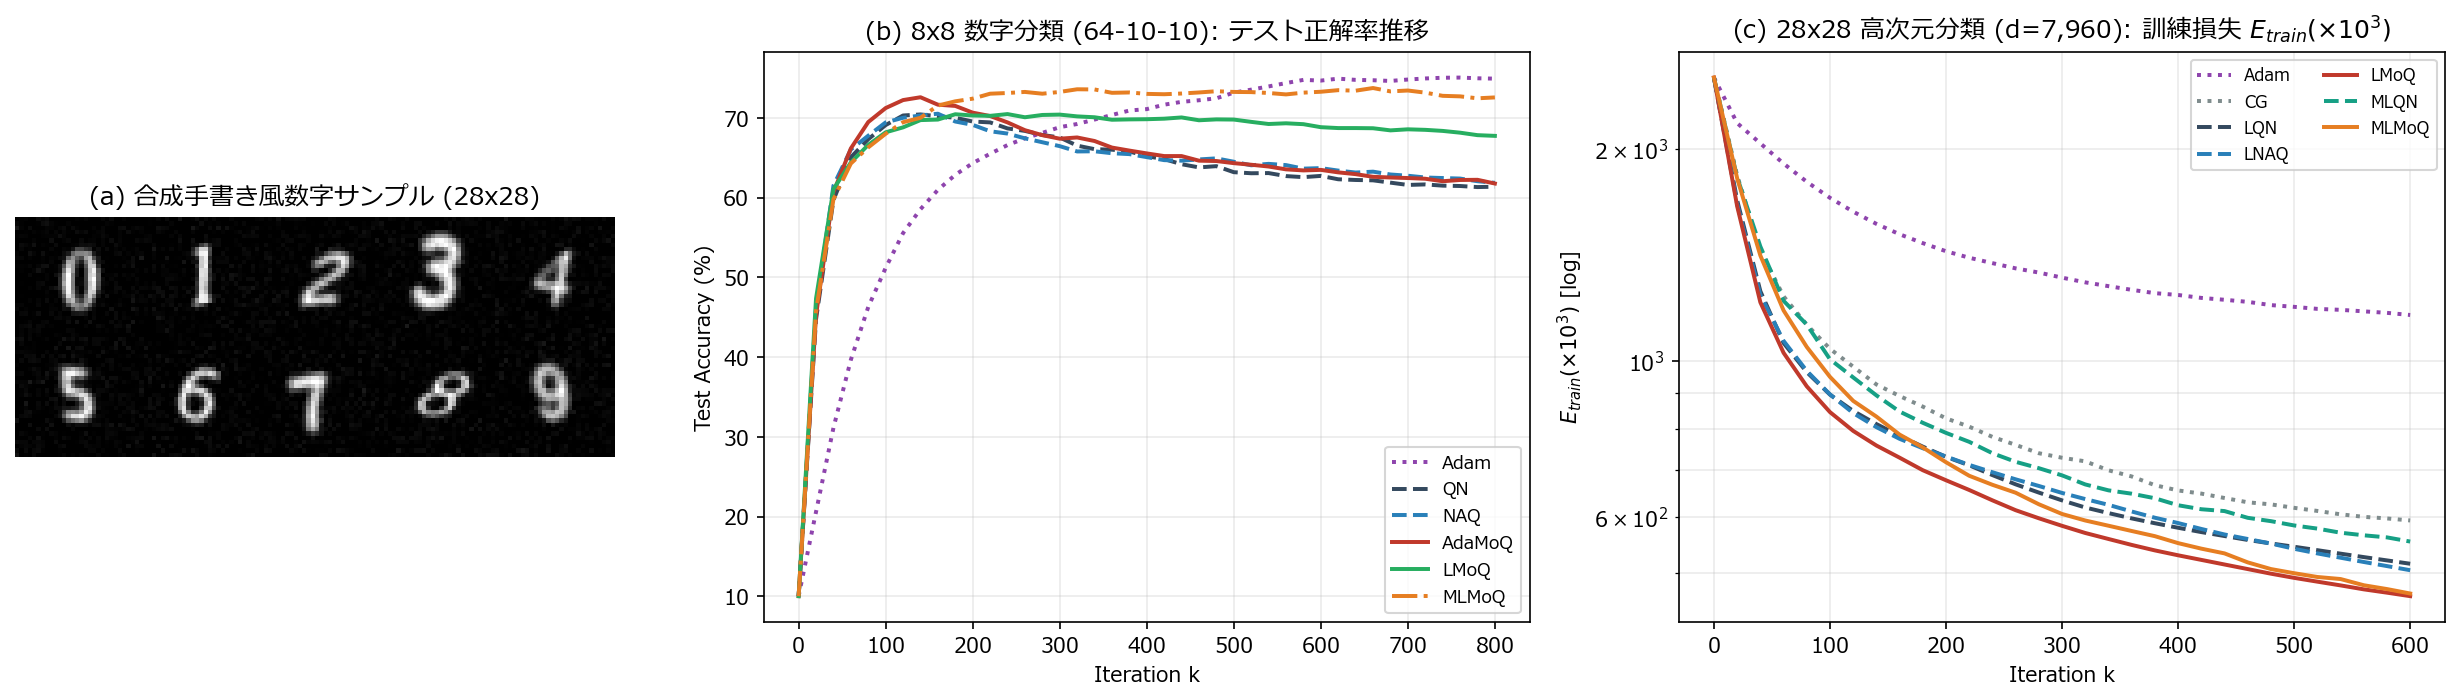

In [6]:
# 図3: 数字画像サンプル & 8x8 / 28x28 の収束曲線比較
fig = plt.figure(figsize=(16.5, 4.8))
gs = fig.add_gridspec(1, 3, width_ratios=[0.9, 1.15, 1.15])

# (a) 28x28 生成画像サンプル (0〜9)
ax0 = fig.add_subplot(gs[0])
ax0.set_title('(a) 合成手書き風数字サンプル (28x28)')
ax0.axis('off')
X_img_28 = ds_28['X_tr_img']
y_raw_28 = ds_28['y_tr_raw']
mosaic = np.zeros((2 * 28, 5 * 28), dtype=np.float32)
for digit in range(10):
    idx = int(np.where(y_raw_28 == digit)[0][0])
    img_d = (X_img_28[idx].reshape(28, 28) + 1.0) * 0.5
    r_pos, c_pos = digit // 5, digit % 5
    mosaic[r_pos * 28:(r_pos + 1) * 28, c_pos * 28:(c_pos + 1) * 28] = img_d
ax0.imshow(mosaic, cmap='gray')

# (b) 8x8 テスト正解率推移
ax1 = fig.add_subplot(gs[1])
for name, col, ls in [
    ('Adam', '#8e44ad', ':'), ('QN', '#34495e', '--'), ('NAQ', '#2980b9', '--'),
    ('AdaMoQ', '#c0392b', '-'), ('LMoQ', '#27ae60', '-'), ('MLMoQ', '#e67e22', '-.')
]:
    r = res_3b_map[name]
    ax1.plot(r['rec_epochs'], r['rec_te_accs'], label=name, color=col, linestyle=ls, linewidth=1.9)
ax1.set_title('(b) 8x8 数字分類 (64-10-10): テスト正解率推移')
ax1.set_xlabel('Iteration k'); ax1.set_ylabel('Test Accuracy (%)')
ax1.legend(fontsize=8.5, loc='lower right'); ax1.grid(alpha=0.25)

# (c) 28x28 平均訓練損失推移
ax2 = fig.add_subplot(gs[2])
for name, col, ls in [
    ('Adam', '#8e44ad', ':'), ('CG', '#7f8c8d', ':'), ('LQN', '#34495e', '--'),
    ('LNAQ', '#2980b9', '--'), ('LMoQ', '#c0392b', '-'), ('MLQN', '#16a085', '--'), ('MLMoQ', '#e67e22', '-')
]:
    r = res_3c_map[name]
    ax2.plot(r['rec_epochs'], np.clip(r['rec_means'] * 1e3, 1e-4, None), label=name, color=col, linestyle=ls, linewidth=1.9)
ax2.set_yscale('log')
ax2.set_title('(c) 28x28 高次元分類 (d=7,960): 訓練損失 $E_{train} (\\times 10^3)$')
ax2.set_xlabel('Iteration k'); ax2.set_ylabel('$E_{train} (\\times 10^3)$ [log]')
ax2.legend(fontsize=8, ncol=2); ax2.grid(alpha=0.25, which='both')

plt.tight_layout()
plt.savefig('../report/img/ex003_digits_convergence.png', dpi=150, bbox_inches='tight')
plt.show()